In [1]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pyvista as pv
from desmin_reconstruction.plotting import save_panel
from desmin_reconstruction.plotting.overlays import compose_overlays, render_overlays
from desmin_reconstruction.plotting.renderings import (
    render_pointcloud,
)
from desmin_reconstruction.preprocessing.bbox import BoundingSquare, filter_bounded
from IPython.display import display, SVG
from matplotlib.offsetbox import AnnotationBbox, HPacker, TextArea
from matplotlib.patches import Rectangle
from matplotlib.ticker import FormatStrFormatter


plt.rc("font", size=12)
plt.rc("grid", linestyle="--", color="lightgray")
plt.rc("axes.spines", right=False, top=False)
pv.set_jupyter_backend("static")

COLOR_DICT = {"desmin": "#CC3311", "actinin": "#009988"}

datadir = Path("../../data/")

In [2]:
filepath = datadir / "results/desmin_alphaactinin_2.5um_filtered_small.csv"
df = pl.read_csv(filepath)
df = df.with_columns(*[pl.col(i) - pl.col(i).min() for i in ("x", "y", "z")])

points = {
    name: df_.select(["x", "y", "z"]).to_numpy()
    for name, df_ in zip(("desmin", "actinin"), df.partition_by("probe"))
}


2026-09-28 11:59:39.294 (   2.572s) [    148D14DB4740]vtkXOpenGLRenderWindow.:1416  WARN| bad X server connection. DISPLAY=


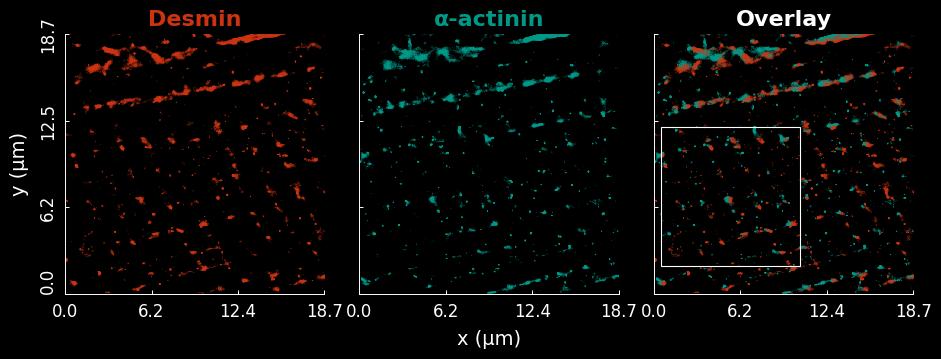

In [3]:
rendered = render_overlays(
    points,
    COLOR_DICT,
    render_pointcloud,
    xy_bounds=None,  # Common bounds from both point clouds
    height_px=700,
    opacity=0.2,
    point_size=1.0,
)

fig, axes = compose_overlays(
    rendered,
    roi=(0.5, 2.0, 10.0, 10.0),  # Left, bottom, width, height
    titles=("Desmin", "α-actinin", "Overlay"),
    panel_height=2.6,  # Inches
    panel_gap=0.35,  # Horizontal gap between panels, inches
    xlabel_fontsize=14,
    ylabel_fontsize=14,
    xtick_fontsize=12,
    ytick_fontsize=12,
    title_fontsize=16,
    xtick_pad=6,  # All padding below is in points
    ytick_pad=6,
    xlabel_pad=7,  # Smaller = common X title closer to panels
    ylabel_pad=7,
    ytick_rotation=90,
    tick_format="%.1f",
)


In [4]:
savepath = "../../figures/1b_1"
save_panel(fig, savepath, formats=("svg",))

[PosixPath('../../figures/1b_1.svg')]

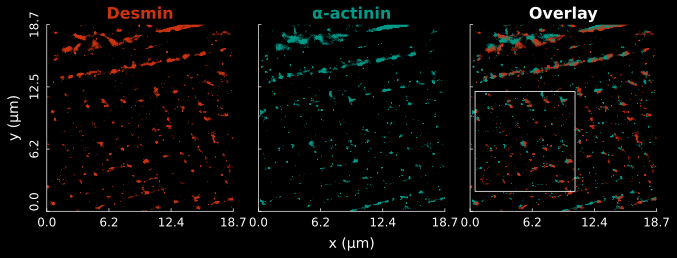

In [6]:
display(SVG(filename=str(savepath+".svg")))
plt.close(fig)

In [10]:
@dataclass(frozen=True)
class RenderedView:
    image: np.ndarray
    extent: tuple  # Requested xmin, xmax, ymin, ymax in physical coordinates.
    image_extent: tuple  # Actual camera coverage, including pixel rounding.


@dataclass(frozen=True)
class RenderedLowerRow:
    views: tuple
    desmin_color: tuple


def render_lower_row(
    points_roi,
    points_roi2,
    colors,
    render_pointcloud,
    *,
    protein_names=("desmin", "actinin"),
    xy_bounds=((0.5, 10.5, 2.0, 12.0), (2.9, 6.4, 4.7, 8.2)),
    height_px=700,
    opacities=(0.4, 0.7),
    point_sizes=(2.0, 4.0),
):
    """Render the two already-filtered ROIs in parallel XY projection.

    Filtering must retain the original point coordinates, as in the supplied
    notebook code. Bounds are camera windows, not a substitute for filtering.
    Each xy_bounds entry is (xmin, xmax, ymin, ymax); set an entry to None
    to fit that scene's occupied point bounds, as show_bounds did originally.
    Both defaults use the full, exact selection squares.

    opacities and point_sizes are (larger ROI, zoom). They are passed unchanged
    to your render_pointcloud helper. The helper must add to the supplied
    Plotter and return that Plotter or None. Both channels are rendered together.

    With ordinary VTK pixel-sized points, increase point_sizes proportionally
    when increasing height_px to preserve relative dot sizes at a fixed layout.
    """
    import pyvista as pv

    if any(len(values) != 2 for values in (xy_bounds, opacities, point_sizes)):
        raise ValueError("xy_bounds, opacities and point_sizes need two entries.")
    names = tuple(protein_names)
    if not names:
        raise ValueError("At least one protein is required.")
    height_px = int(height_px)
    if height_px < 2:
        raise ValueError("height_px must be at least 2.")
    views = []
    for subset, requested, opacity, point_size in zip(
        (points_roi, points_roi2), xy_bounds, opacities, point_sizes
    ):
        p = pv.Plotter(off_screen=True, window_size=(height_px, height_px))
        try:
            p.set_background("black")
            for name in names:
                result = render_pointcloud(
                    p, subset[name], color=colors[name],
                    opacity=opacity, point_size=point_size,
                )
                if result is not None and result is not p:
                    raise ValueError("render_pointcloud must use the supplied Plotter.")

            scene = np.asarray(p.bounds, dtype=float)
            extent = np.asarray(scene[:4] if requested is None else requested, dtype=float)
            if extent.shape != (4,) or not np.all(np.isfinite(extent)):
                raise ValueError("Each view needs four finite bounds.")
            if not np.all(np.isfinite(scene)) or scene[5] < scene[4]:
                raise ValueError("The scene must have valid point-cloud bounds.")
            x0, x1, y0, y1 = extent
            dx, dy = x1 - x0, y1 - y0
            if dx <= 0 or dy <= 0:
                raise ValueError("X and Y bounds must be increasing.")
            width_px = max(2, int(np.ceil(height_px * dx / dy)))
            p.window_size = (width_px, height_px)
            cx, cy, cz = (x0 + x1) / 2, (y0 + y1) / 2, (scene[4] + scene[5]) / 2
            distance = 2 * max(dx, dy, scene[5] - scene[4])
            p.enable_parallel_projection()
            p.camera_position = [(cx, cy, cz + distance), (cx, cy, cz), (0, 1, 0)]
            p.camera.parallel_scale = dy / 2
            p.reset_camera_clipping_range()
            half_width = (dy / 2) * width_px / height_px
            image_extent = (cx - half_width, cx + half_width, y0, y1)
            p.render()
            image = np.array(p.screenshot(transparent_background=False), copy=True)
            views.append(RenderedView(image, tuple(extent), image_extent))
        finally:
            p.close()
    desmin_color = pv.Color(colors[names[0]]).float_rgb
    return RenderedLowerRow(tuple(views), desmin_color)


def compose_lower_row(
    rendered,
    *,
    roi_box=(2.9, 4.7, 3.5, 3.5),
    panel_height=2.9,
    panel_gap=1.45,
    top_margin=0.85,
    xlabel_fontsize=14,
    ylabel_fontsize=14,
    xtick_fontsize=11,
    ytick_fontsize=11,
    xtick_pad=7,
    ytick_pad=10,
    xlabel_pad=8,
    ylabel_pad=10,
    ytick_rotation=90,
    tick_format="%.1f",
    xticks=None,
    yticks=None,
    font_family="DejaVu Sans",
    roi_linewidth=0.8,
):
    """Arrange both views at equal height, preserving their physical aspect.

    These views have DIFFERENT coordinate ranges, so their axes are independent.
    Both show X/Y ticks and numbers; the row has common x (µm) and y (µm) titles.
    X labels are centred on every tick. The lowest Y label extends upward to
    keep it clear of the X labels.

    panel_height, panel_gap and top_margin are in inches. Font sizes, all other
    padding, and linewidths are in points. The gap reserves space for arrows,
    vertical text, and the right panel's Y tick labels. Decrease xlabel_pad to
    bring the common X title closer. top_margin reserves space for the bracket.

    roi_box is (left, bottom, width, height) on the larger ROI; None hides it.
    xticks/yticks may each be a pair of per-panel arrays (or None entries).
    """
    if len(rendered.views) != 2:
        raise ValueError("Exactly two rendered views are required.")
    if panel_height <= 0 or panel_gap < 0 or top_margin < 0:
        raise ValueError("Use a positive panel height and nonnegative margins.")
    widths = [panel_height * (v.extent[1] - v.extent[0]) / (v.extent[3] - v.extent[2]) for v in rendered.views]
    xchoices = (None, None) if xticks is None else xticks
    ychoices = (None, None) if yticks is None else yticks
    if len(xchoices) != 2 or len(ychoices) != 2:
        raise ValueError("xticks and yticks each need two per-panel entries.")
    left = max(0.75, (ytick_pad + ylabel_pad + 1.3 * (ytick_fontsize + ylabel_fontsize) + 8) / 72)
    bottom = max(0.65, (xtick_pad + xlabel_pad + 1.3 * (xtick_fontsize + xlabel_fontsize) + 8) / 72)
    right = 0.28
    total_width = sum(widths) + panel_gap
    fw, fh = left + total_width + right, bottom + panel_height + top_margin

    with mpl.rc_context({"font.family": font_family}):
        fig = plt.figure(figsize=(fw, fh), facecolor="black")
        axes = []
        xpos = left
        for i, (view, width) in enumerate(zip(rendered.views, widths)):
            x0, x1, y0, y1 = view.extent
            ax = fig.add_axes([xpos / fw, bottom / fh, width / fw, panel_height / fh], facecolor="black")
            ax.imshow(view.image, extent=view.image_extent, origin="upper", aspect="equal", interpolation="none")
            ax.set_xticks(np.linspace(x0, x1, 5) if xchoices[i] is None else xchoices[i])
            ax.set_yticks(np.linspace(y0, y1, 5) if ychoices[i] is None else ychoices[i])
            ax.set_xlim(x0, x1)
            ax.set_ylim(y0, y1)
            ax.set_autoscale_on(False)  # Annotations outside the panel must not change limits.
            ax.xaxis.set_major_formatter(FormatStrFormatter(tick_format))
            ax.yaxis.set_major_formatter(FormatStrFormatter(tick_format))
            ax.tick_params(colors="white", direction="in", length=3, width=0.7)
            ax.tick_params(axis="x", labelsize=xtick_fontsize, pad=xtick_pad)
            ax.tick_params(axis="y", labelsize=ytick_fontsize, pad=ytick_pad, labelrotation=ytick_rotation)
            for side, spine in ax.spines.items():
                spine.set_visible(side in ("left", "bottom"))
                spine.set_color("white")
                spine.set_linewidth(0.7)
            for label in ax.get_xticklabels():
                label.set_ha("center")
            for value, label in zip(ax.get_yticks(), ax.get_yticklabels()):
                label.set_va("bottom" if np.isclose(value, y0) else "center")
            axes.append(ax)
            xpos += width + panel_gap

        if roi_box is not None:
            rx, ry, rw, rh = roi_box
            axes[0].add_patch(Rectangle(
                (rx, ry), rw, rh, fill=False, edgecolor="white",
                linewidth=roi_linewidth, clip_on=False, zorder=5,
            ))
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        xboxes = [t.get_window_extent(renderer) for ax in axes for t in ax.get_xticklabels() if t.get_visible()]
        yboxes = [t.get_window_extent(renderer) for t in axes[0].get_yticklabels() if t.get_visible()]
        inverse = fig.transFigure.inverted()
        xlabel_y = inverse.transform((0, min(b.y0 for b in xboxes)))[1] - xlabel_pad / (72 * fh)
        ylabel_x = inverse.transform((min(b.x0 for b in yboxes), 0))[0] - ylabel_pad / (72 * fw)
        fig.supxlabel("x (µm)", x=(left + total_width / 2) / fw, y=xlabel_y, va="top", color="white", fontsize=xlabel_fontsize)
        fig.supylabel("y (µm)", x=ylabel_x, y=(bottom + panel_height / 2) / fh, ha="right", color="white", fontsize=ylabel_fontsize)
    return fig, tuple(axes)


def add_lower_annotations(
    axes,
    *,
    desmin_color="red",
    font_family="DejaVu Sans",
    show_zlines=True,
    zline_start=(1.2, 12.8),
    zline_end=(8.8, 13.0),
    zline_label_xy=(0.5, 13.6),
    zline_nticks=5,
    zline_tick_length=8,
    zline_fontsize=12,
    zline_linewidth=0.8,
    show_desmin=True,
    desmin_tip_x=10.65,
    desmin_tip_ys=(11.5, 10.1, 7.8, 6.0, 4.5, 3.6),
    arrow_offset=(14, 4),
    arrow_headsize=12,
    arrow_linewidth=1.2,
    desmin_label_xy=(1.28, 0.5),
    desmin_label_fontsize=13,
    show_caption=True,
    caption_xy=(0.5, 1.08),
    caption_fontsize=12,
):
    """Add the reference's Z-line bracket, red arrows/text, and zoom caption.

    Bracket endpoints, its label position, and arrow tips use the LEFT panel's
    data coordinates (µm). arrow_offset is (dx, dy) in points from tip to tail.
    zline_tick_length, font sizes and linewidths are in points. The bracket's
    short ticks point downward, perpendicular to its baseline.

    desmin_label_xy is in LEFT axes fractions; caption_xy is in RIGHT axes
    fractions. Positions outside 0..1 place labels outside the image.

    Default marker positions approximate the supplied figure and need alignment
    to the actual features. Call once per new figure; the returned dictionary
    holds the artists for later editing or removal.
    """
    left, right = axes
    artists = {}
    if show_zlines:
        if zline_nticks < 2:
            raise ValueError("zline_nticks must be at least 2.")
        start, end = np.asarray(zline_start, dtype=float), np.asarray(zline_end, dtype=float)
        points = np.linspace(start, end, zline_nticks)
        baseline, = left.plot(points[:, 0], points[:, 1], color="white", lw=zline_linewidth, clip_on=False, zorder=6)
        # Work in display coordinates so the specified tick length is in points.
        screen_start, screen_end = left.transData.transform(np.array([start, end]))
        tangent = screen_end - screen_start
        length = np.linalg.norm(tangent)
        if length == 0:
            raise ValueError("The Z-line bracket endpoints must differ.")
        normal = np.array([tangent[1], -tangent[0]]) / length
        if normal[1] > 0:
            normal *= -1
        delta = normal * zline_tick_length * left.figure.dpi / 72
        tick_artists = []
        for point in points:
            tick_end = left.transData.inverted().transform(left.transData.transform(point) + delta)
            tick, = left.plot([point[0], tick_end[0]], [point[1], tick_end[1]], color="white", lw=zline_linewidth, clip_on=False, zorder=6)
            tick_artists.append(tick)
        artists["zline_baseline"] = baseline
        artists["zline_ticks"] = tick_artists
        artists["zline_label"] = left.text(*zline_label_xy, "Z lines", ha="left", va="bottom", color="white", fontsize=zline_fontsize, fontfamily=font_family, clip_on=False)

    if show_desmin:
        arrows = []
        for tip_y in desmin_tip_ys:
            arrows.append(left.annotate(
                "", xy=(desmin_tip_x, tip_y), xycoords="data",
                xytext=arrow_offset, textcoords="offset points",
                arrowprops=dict(arrowstyle="->", color=desmin_color, mutation_scale=arrow_headsize,
                                lw=arrow_linewidth, shrinkA=0, shrinkB=0, clip_on=False),
                annotation_clip=False, zorder=6,
            ))
        artists["desmin_arrows"] = arrows
        artists["desmin_label"] = left.text(
            *desmin_label_xy, "Horizontal distribution of desmin IF",
            transform=left.transAxes, rotation=270, ha="center", va="center",
            color=desmin_color, fontsize=desmin_label_fontsize, fontfamily=font_family, clip_on=False, weight="semibold"
        )

    if show_caption:
        common = dict(fontsize=caption_fontsize, fontfamily=font_family, weight="semibold")
        first = TextArea("Desmin", textprops=dict(color=desmin_color, **common))
        rest = TextArea(" is observed between the Z lines", textprops=dict(color="white", **common))
        packed = HPacker(children=[first, rest], align="baseline", pad=0, sep=0)
        caption = AnnotationBbox(
            packed, caption_xy, xycoords="axes fraction", box_alignment=(0.5, 0),
            frameon=False, pad=0, annotation_clip=False,
        )
        caption.set_clip_on(False)
        right.add_artist(caption)
        artists["zoom_caption"] = caption
    return artists

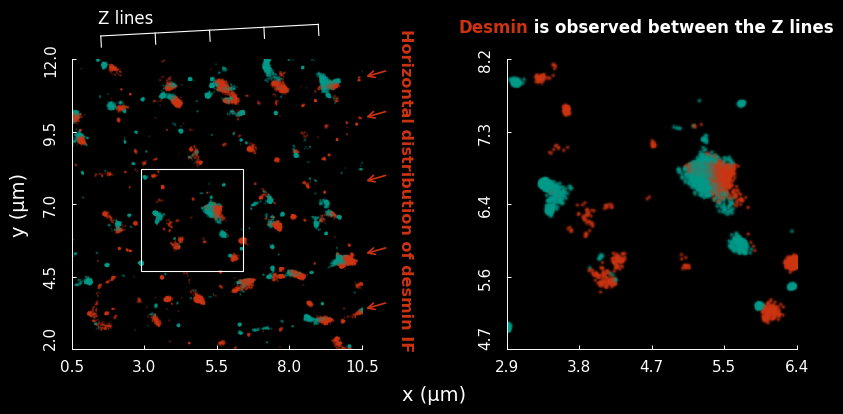

In [15]:

# 1. Filter using your existing helpers.
bbox = BoundingSquare(0.5, 2, side=10)
bbox2 = BoundingSquare(2.9, 4.7, side=3.5)

points_roi = {
    k: filter_bounded(v, bbox)
    for k, v in points.items()
}
points_roi2 = {
    k: filter_bounded(v, bbox2)
    for k, v in points_roi.items()
}

# 2. Render once.
rendered = render_lower_row(
    points_roi,
    points_roi2,
    COLOR_DICT,
    render_pointcloud,
    height_px=700,
    opacities=(0.4, 0.7),
    point_sizes=(2.0, 4.0),
)

# 3. Repeat from here when adjusting formatting.
fig, axes = compose_lower_row(
    rendered,
    panel_height=2.9,     # Inches
    panel_gap=1.45,       # Space for the central annotation
    xlabel_fontsize=14,
    ylabel_fontsize=14,
    xtick_fontsize=11,
    ytick_fontsize=11,
    xlabel_pad=8,        # Points; smaller brings X title closer
)

roi_ax, zoom_ax = axes

annotations = add_lower_annotations(
    axes,
    desmin_color=rendered.desmin_color,

    # Bracket positions in the LEFT panel's data coordinates.
    zline_start=(1.5, 12.8),
    zline_end=(9.0, 13.2),
    zline_nticks=5,
    zline_tick_length=8,  # Points
    zline_label_xy=(1.4, 13.1),
    desmin_tip_ys=(11.4, 10.0, 7.8, 5.3, 3.4),
    desmin_label_xy=(1.15, 0.55),
    desmin_label_fontsize=11.5,
    arrow_offset=(14, 4), # Tail offset in points
    arrow_headsize=12,
    arrow_linewidth=1.2,
    caption_xy=(0.48, 1.08),
)


display(fig)


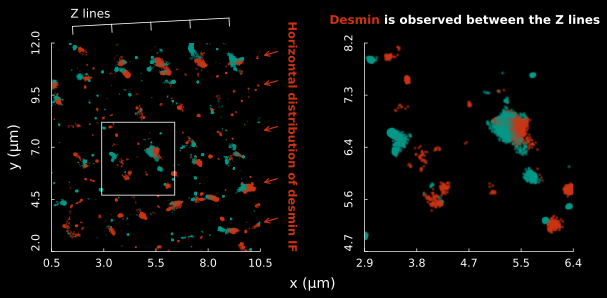

In [ ]:
savepath = "../../figures/1b_2"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath+".svg")))
plt.close(fig)

In [46]:
save_panel(fig, "../figures/1b_2", formats=("svg",))

[PosixPath('../figures/1b_2.svg')]